In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from google.colab import files

print("Library berhasil diimport.")

Library berhasil diimport.


In [45]:
uploaded = files.upload()

Saving WhatsApp Image 2026-09-18 at 14.07.17.jpeg to WhatsApp Image 2026-09-18 at 14.07.17 (3).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.18 (1).jpeg to WhatsApp Image 2026-09-18 at 14.07.18 (1) (3).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.18.jpeg to WhatsApp Image 2026-09-18 at 14.07.18 (4).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.19 (1).jpeg to WhatsApp Image 2026-09-18 at 14.07.19 (1) (3).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.19 (2).jpeg to WhatsApp Image 2026-09-18 at 14.07.19 (2) (3).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.19.jpeg to WhatsApp Image 2026-09-18 at 14.07.19 (5).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.20 (1).jpeg to WhatsApp Image 2026-09-18 at 14.07.20 (1) (3).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.20.jpeg to WhatsApp Image 2026-09-18 at 14.07.20 (4).jpeg
Saving WhatsApp Image 2026-09-18 at 14.07.21.jpeg to WhatsApp Image 2026-09-18 at 14.07.21 (3).jpeg


In [46]:
x1_present = 650
y1_present = 475
x2_present = 890
y2_present = 590

In [47]:
present_cropped = {}

for filename, file_data in uploaded.items():

    image = cv2.imdecode(
        np.frombuffer(file_data, np.uint8),
        cv2.IMREAD_COLOR
    )

    present_crop = image[
        y1_present:y2_present,
        x1_present:x2_present
    ].copy()

    present_cropped[filename] = present_crop

print("Jumlah gambar PRESENT:", len(present_cropped))

Jumlah gambar PRESENT: 9


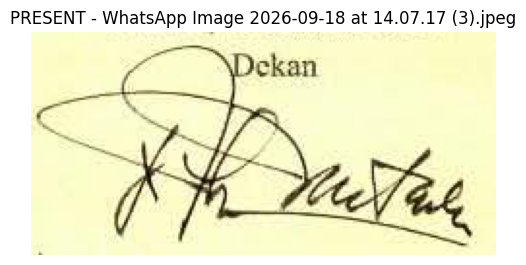

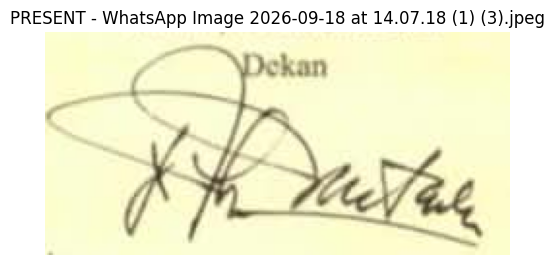

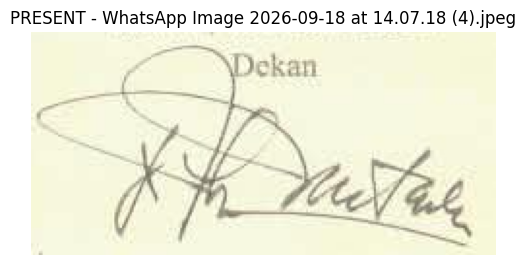

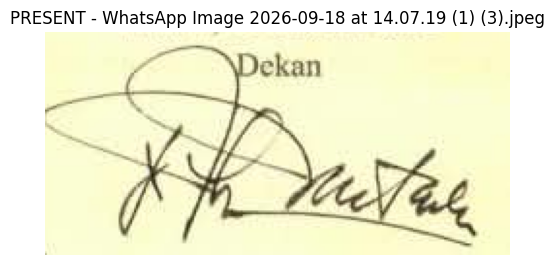

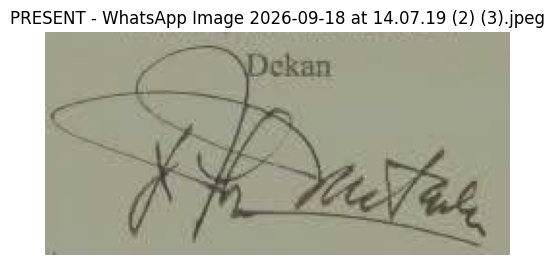

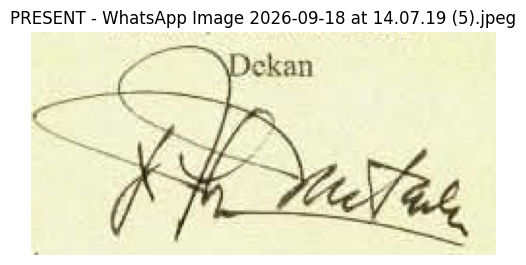

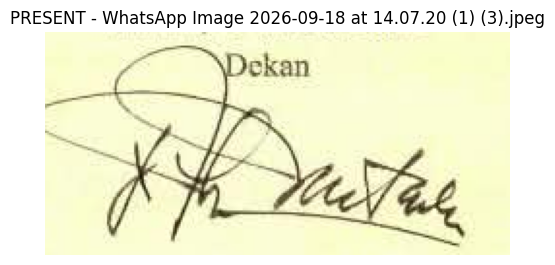

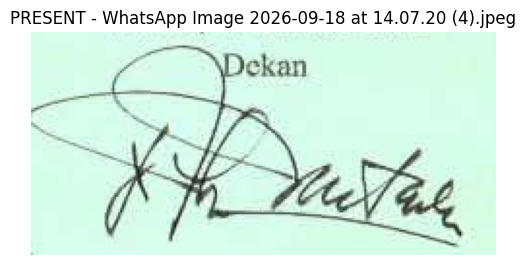

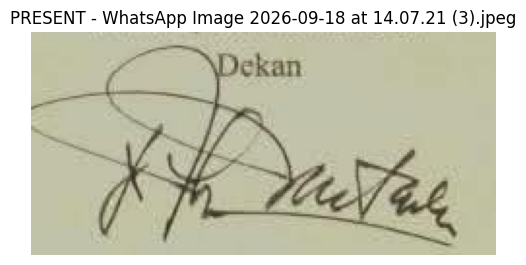

In [48]:
for filename, crop in present_cropped.items():

    plt.figure(figsize=(6, 3))

    crop_rgb = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2RGB
    )

    plt.imshow(crop_rgb)
    plt.title(f"PRESENT - {filename}")
    plt.axis("off")
    plt.show()

In [49]:
absent_cropped = {}

for filename, present_crop in present_cropped.items():

    absent_crop = present_crop.copy()

    # Membuat mask kosong
    mask = np.zeros(
        absent_crop.shape[:2],
        dtype=np.uint8
    )

    # Area tanda tangan yang akan dihapus
    polygon = np.array([
        [0, 45],
        [15, 35],
        [55, 30],
        [95, 35],
        [125, 40],
        [150, 35],
        [175, 45],
        [200, 55],
        [239, 65],
        [239, 115],
        [0, 115]
    ], dtype=np.int32)

    cv2.fillPoly(
        mask,
        [polygon],
        255
    )

    # Memperluas area mask
    cv2.ellipse(
        mask,
        (85, 38),
        (55, 38),
        0,
        0,
        360,
        255,
        -1
    )

    kernel = np.ones(
        (7, 7),
        np.uint8
    )

    mask = cv2.dilate(
        mask,
        kernel,
        iterations=1
    )

    # Menghapus tanda tangan
    absent_crop = cv2.inpaint(
        absent_crop,
        mask,
        5,
        cv2.INPAINT_TELEA
    )

    absent_cropped[filename] = absent_crop

print("Jumlah gambar ABSENT:", len(absent_cropped))

Jumlah gambar ABSENT: 9


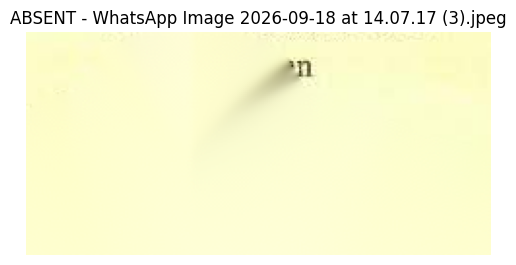

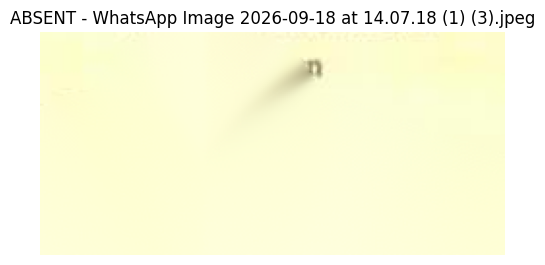

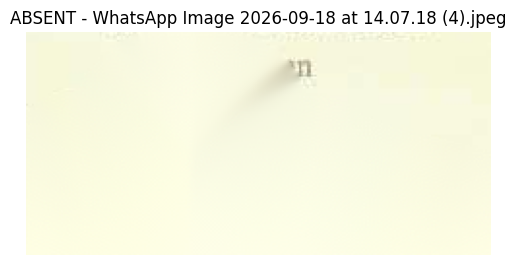

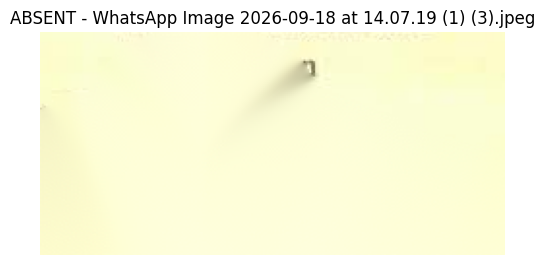

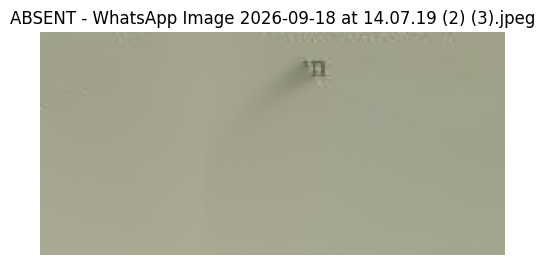

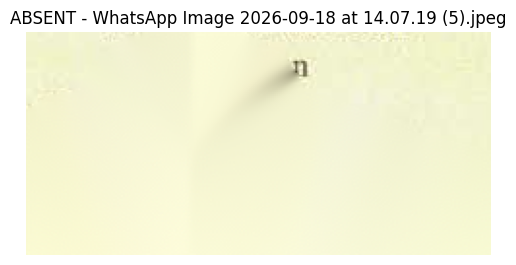

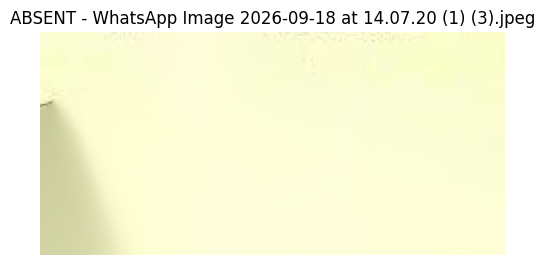

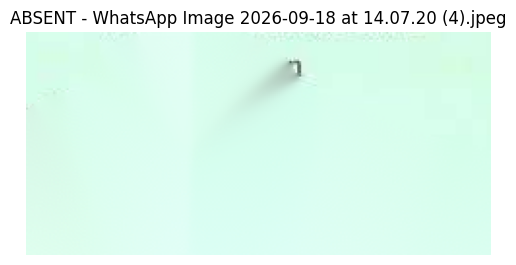

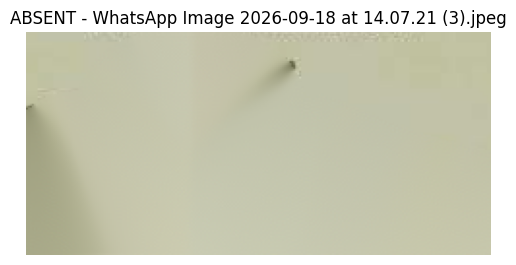

In [50]:
for filename, crop in absent_cropped.items():

    plt.figure(figsize=(6, 3))

    crop_rgb = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2RGB
    )

    plt.imshow(crop_rgb)
    plt.title(f"ABSENT - {filename}")
    plt.axis("off")
    plt.show()

In [52]:
present_gray = {}

for filename, crop in present_cropped.items():

    gray = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    present_gray[filename] = gray

print("Grayscale PRESENT selesai.")

absent_gray = {}

for filename, crop in absent_cropped.items():

    gray = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    absent_gray[filename] = gray

print("Grayscale ABSENT selesai.")

Grayscale PRESENT selesai.
Grayscale ABSENT selesai.


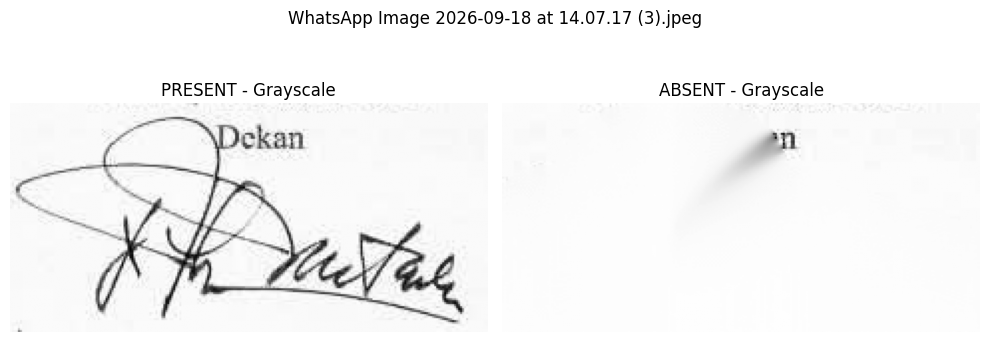

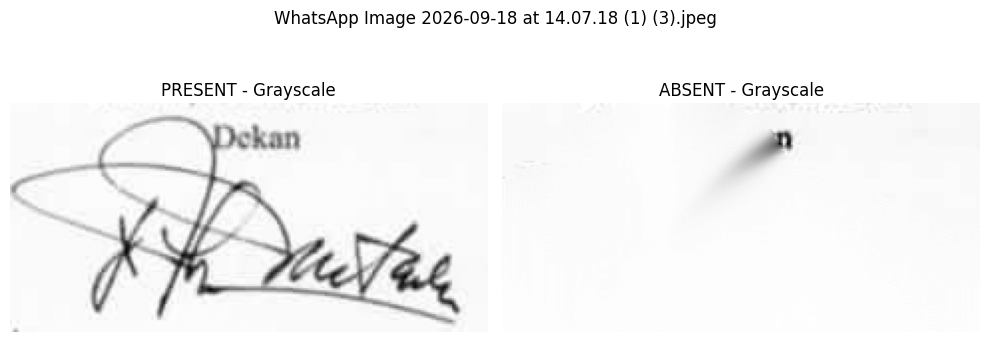

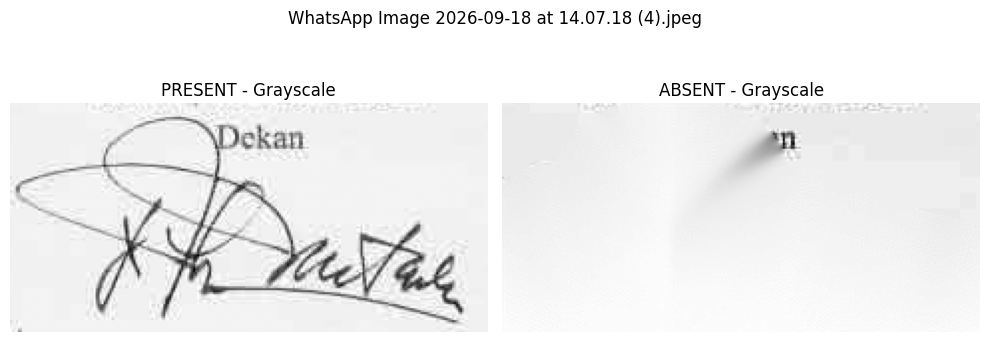

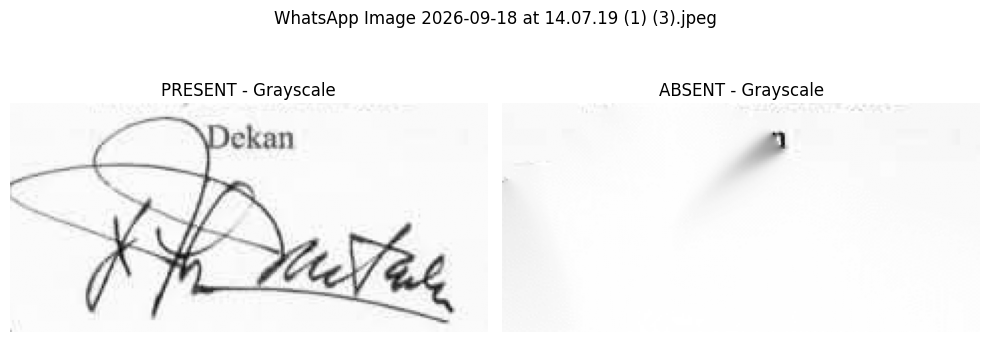

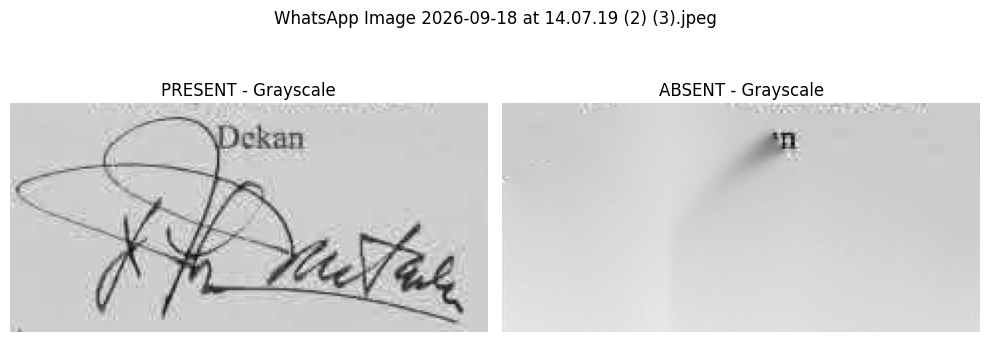

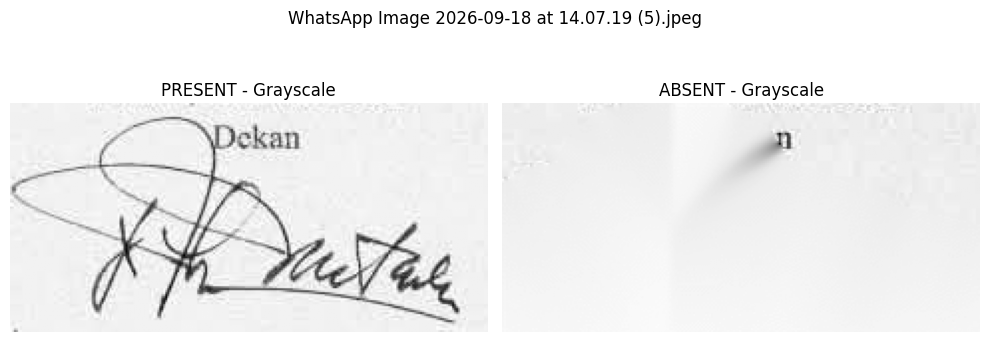

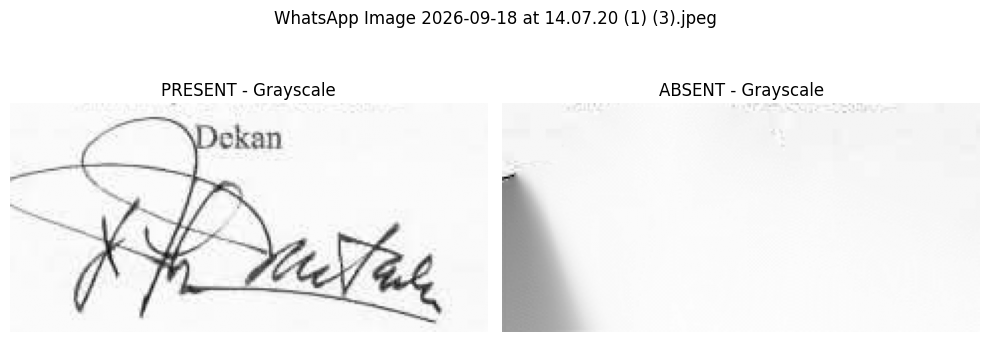

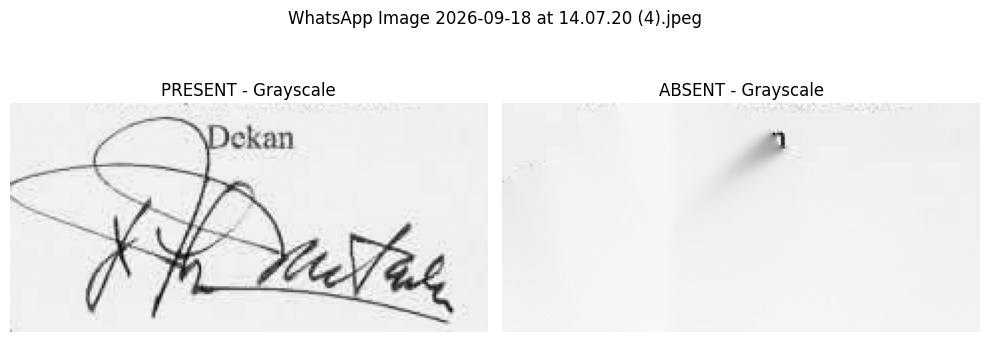

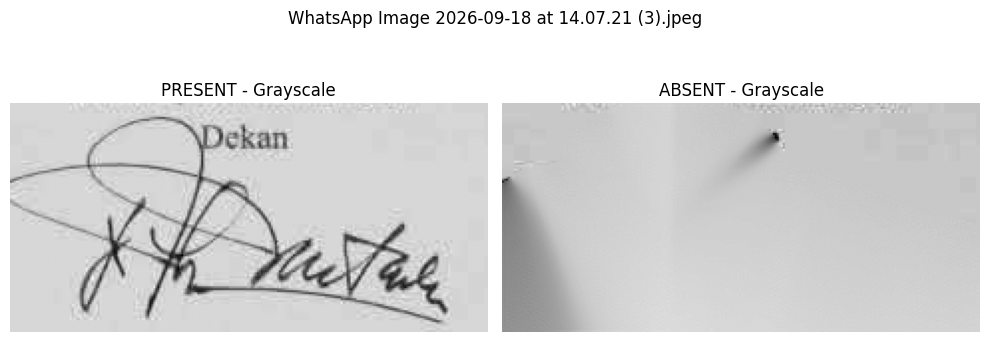

In [53]:
for filename in present_gray.keys():

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 4)
    )

    axes[0].imshow(
        present_gray[filename],
        cmap="gray"
    )
    axes[0].set_title("PRESENT - Grayscale")
    axes[0].axis("off")

    axes[1].imshow(
        absent_gray[filename],
        cmap="gray"
    )
    axes[1].set_title("ABSENT - Grayscale")
    axes[1].axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [54]:
threshold_value = 150

present_global = {}

for filename, gray in present_gray.items():

    _, threshold = cv2.threshold(
        gray,
        threshold_value,
        255,
        cv2.THRESH_BINARY_INV
    )

    present_global[filename] = threshold

print("Global Threshold PRESENT selesai.")

absent_global = {}

for filename, gray in absent_gray.items():

    _, threshold = cv2.threshold(
        gray,
        threshold_value,
        255,
        cv2.THRESH_BINARY_INV
    )

    absent_global[filename] = threshold

print("Global Threshold ABSENT selesai.")

Global Threshold PRESENT selesai.
Global Threshold ABSENT selesai.


In [55]:
present_otsu = {}
present_otsu_values = {}

for filename, gray in present_gray.items():

    otsu_value, threshold = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    present_otsu[filename] = threshold
    present_otsu_values[filename] = otsu_value

print("Otsu PRESENT selesai.")

absent_otsu = {}
absent_otsu_values = {}

for filename, gray in absent_gray.items():

    otsu_value, threshold = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    absent_otsu[filename] = threshold
    absent_otsu_values[filename] = otsu_value

print("Otsu ABSENT selesai.")

Otsu PRESENT selesai.
Otsu ABSENT selesai.


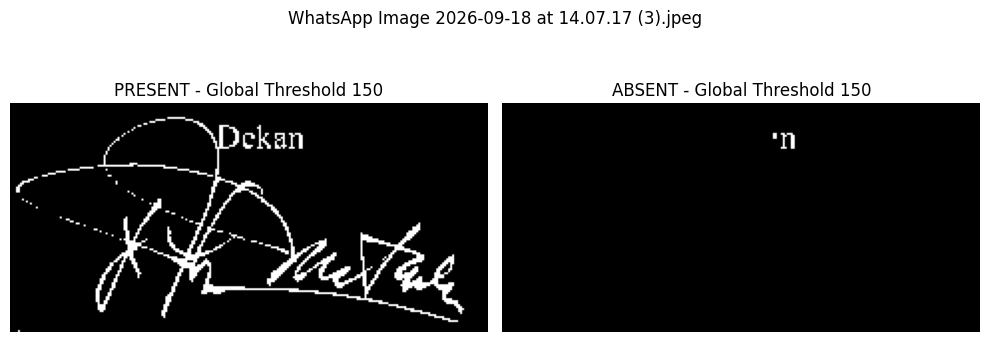

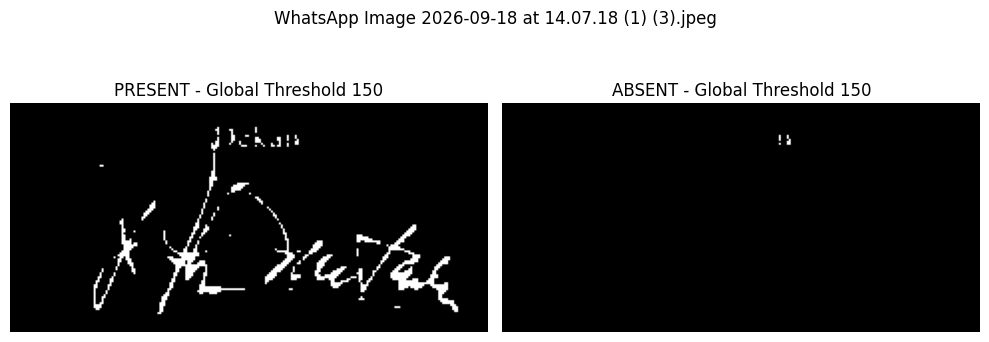

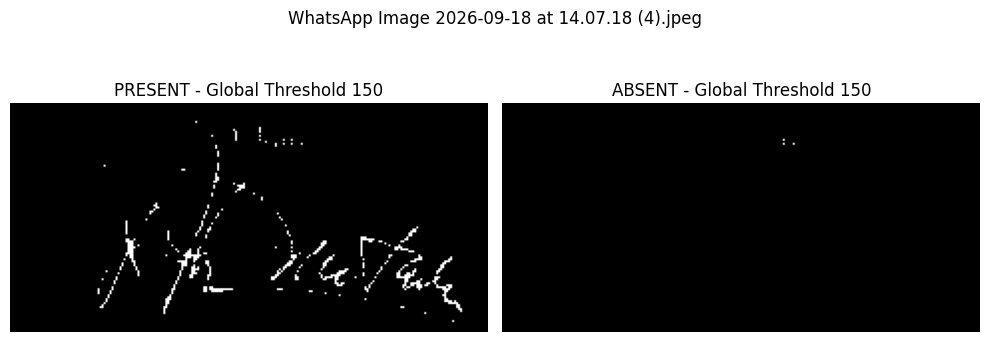

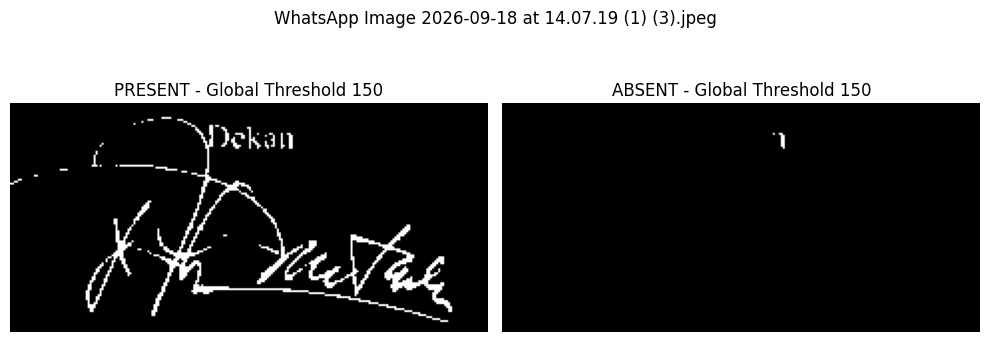

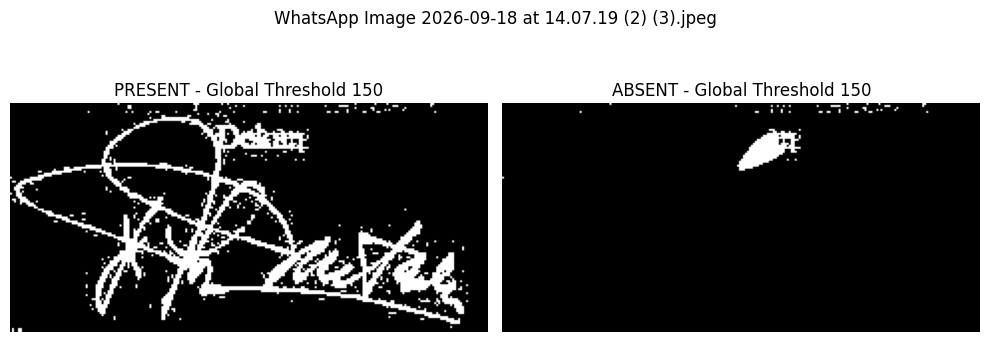

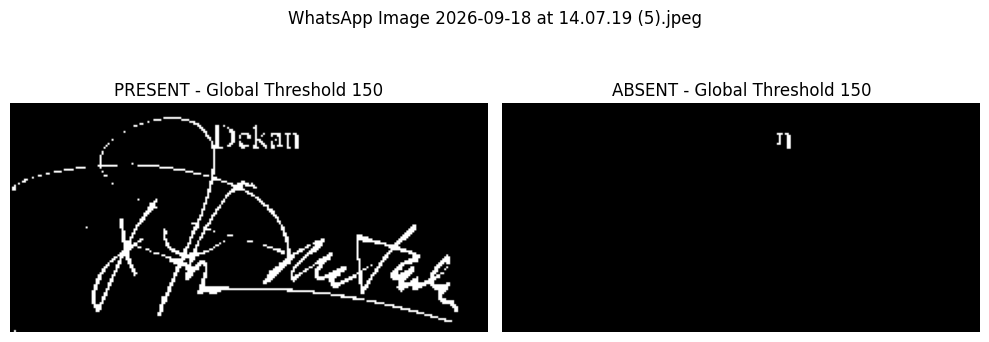

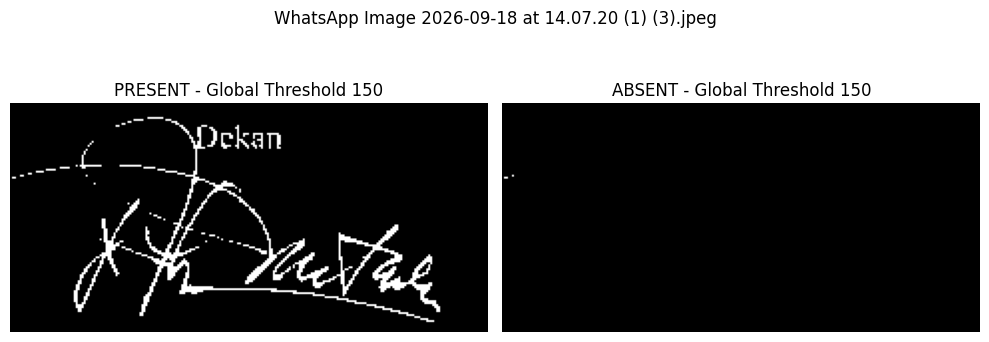

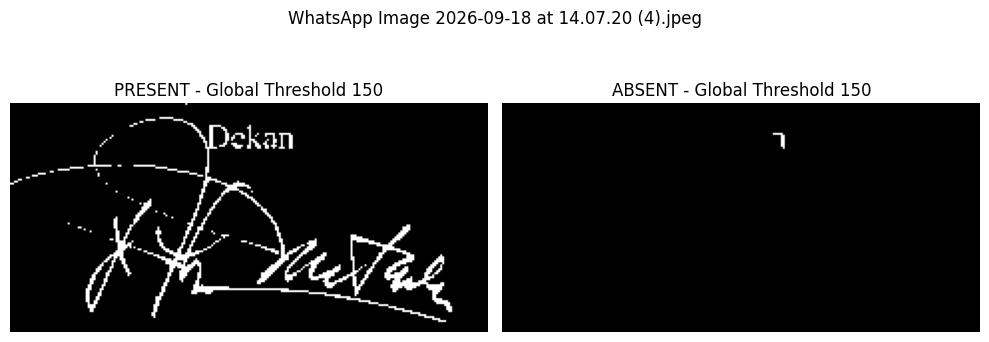

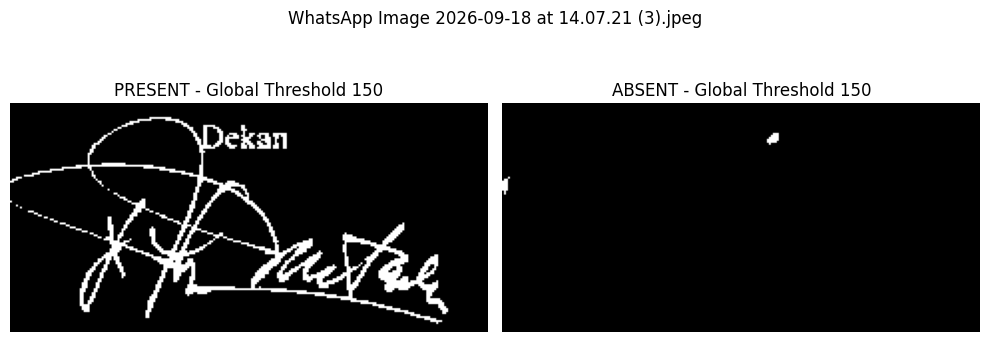

In [56]:
for filename in present_global.keys():

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 4)
    )

    axes[0].imshow(
        present_global[filename],
        cmap="gray"
    )
    axes[0].set_title(
        "PRESENT - Global Threshold 150"
    )
    axes[0].axis("off")

    axes[1].imshow(
        absent_global[filename],
        cmap="gray"
    )
    axes[1].set_title(
        "ABSENT - Global Threshold 150"
    )
    axes[1].axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

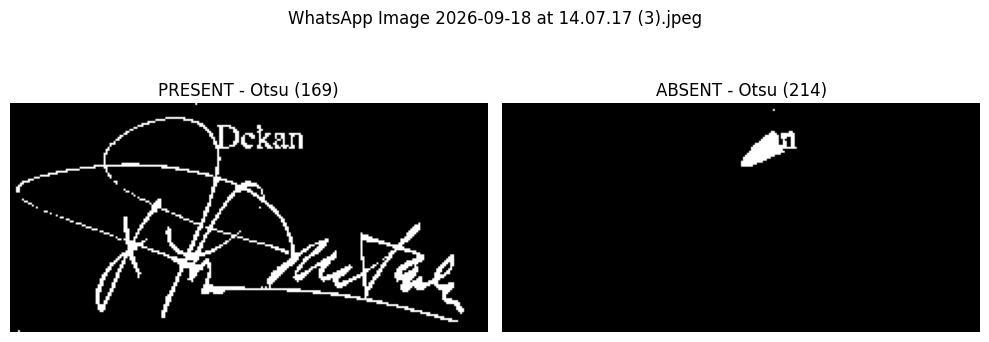

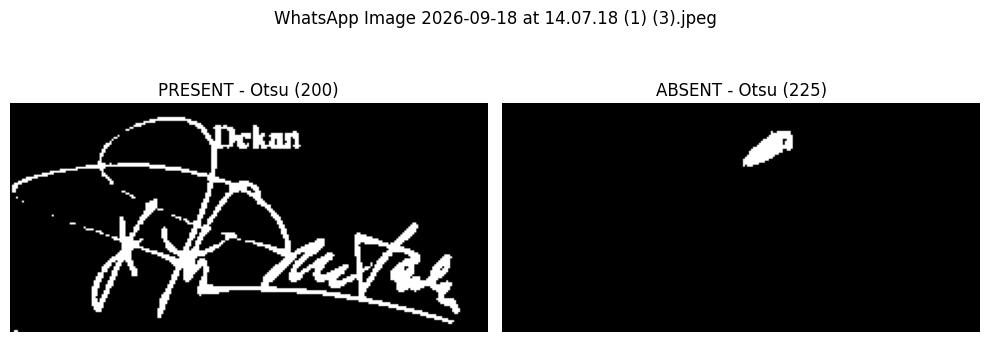

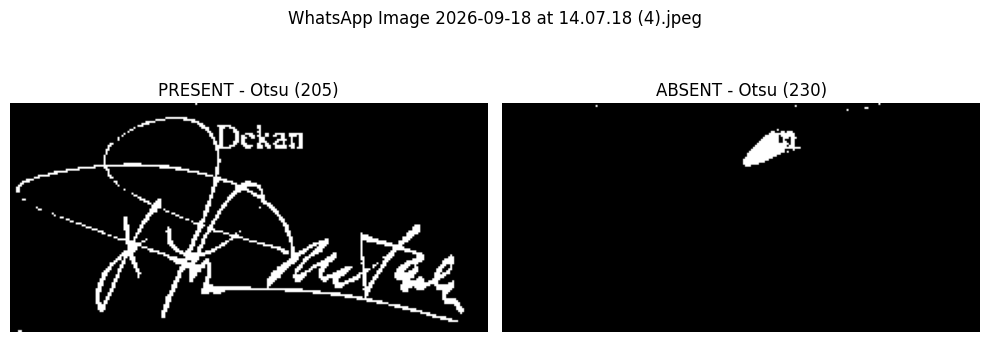

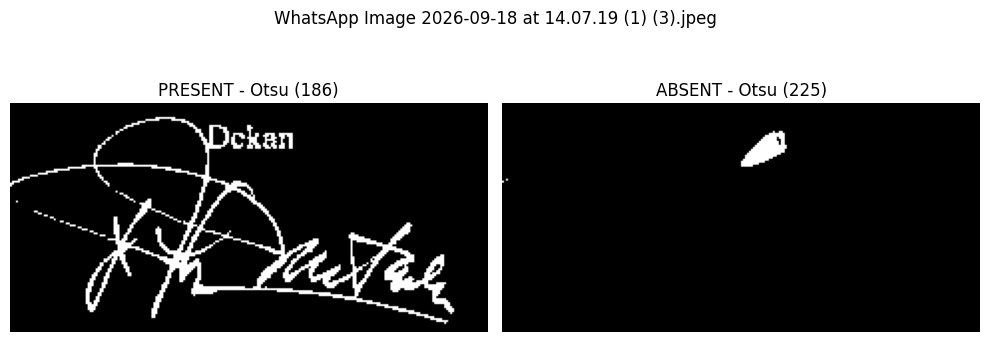

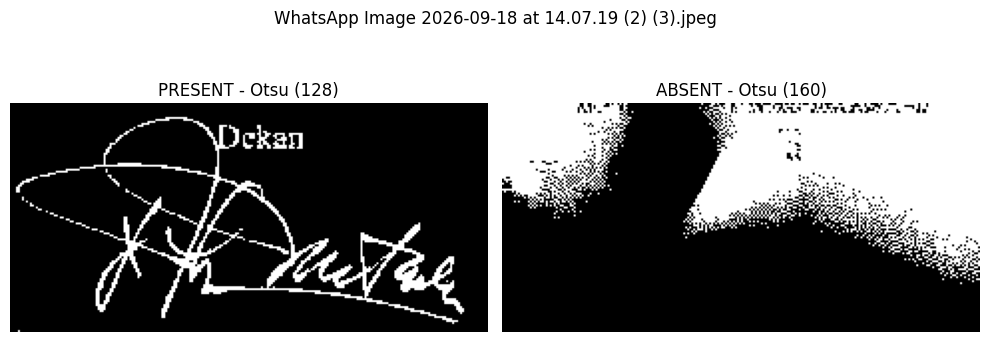

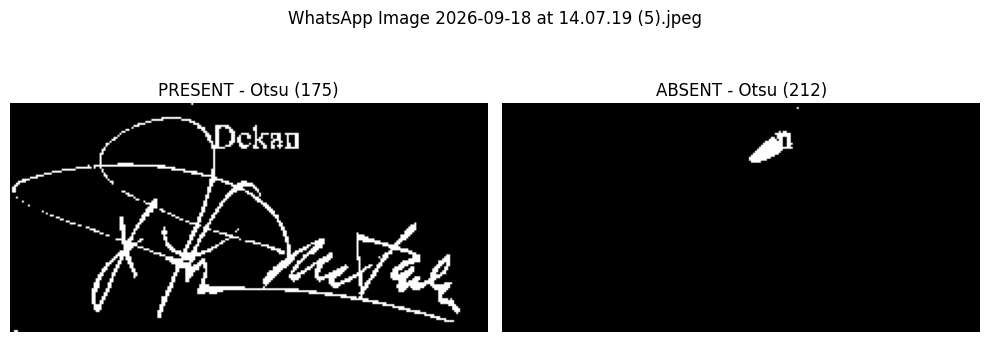

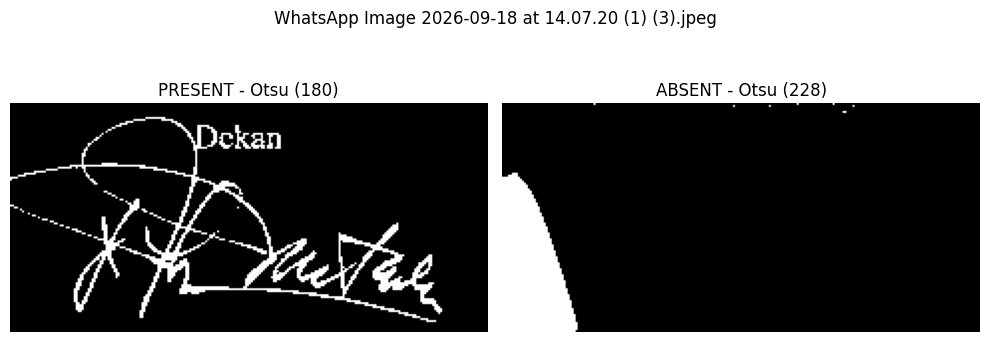

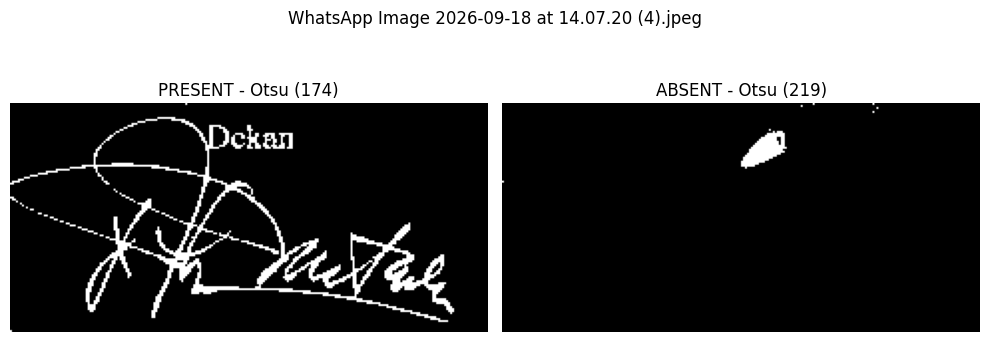

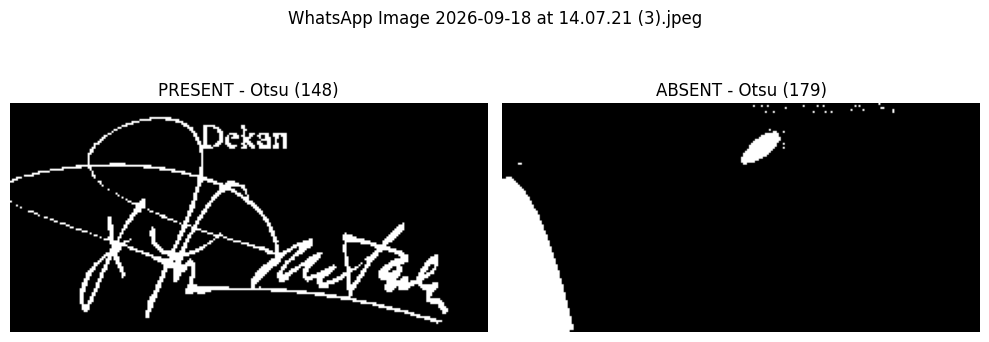

In [57]:
for filename in present_otsu.keys():

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 4)
    )

    axes[0].imshow(
        present_otsu[filename],
        cmap="gray"
    )
    axes[0].set_title(
        f"PRESENT - Otsu ({present_otsu_values[filename]:.0f})"
    )
    axes[0].axis("off")

    axes[1].imshow(
        absent_otsu[filename],
        cmap="gray"
    )
    axes[1].set_title(
        f"ABSENT - Otsu ({absent_otsu_values[filename]:.0f})"
    )
    axes[1].axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [58]:
kernel = np.ones((3, 3), np.uint8)

present_opening = {}
absent_opening = {}

for filename in present_global.keys():

    present_opening[filename] = cv2.morphologyEx(
        present_global[filename],
        cv2.MORPH_OPEN,
        kernel
    )

    absent_opening[filename] = cv2.morphologyEx(
        absent_global[filename],
        cv2.MORPH_OPEN,
        kernel
    )

print("Opening selesai.")

Opening selesai.


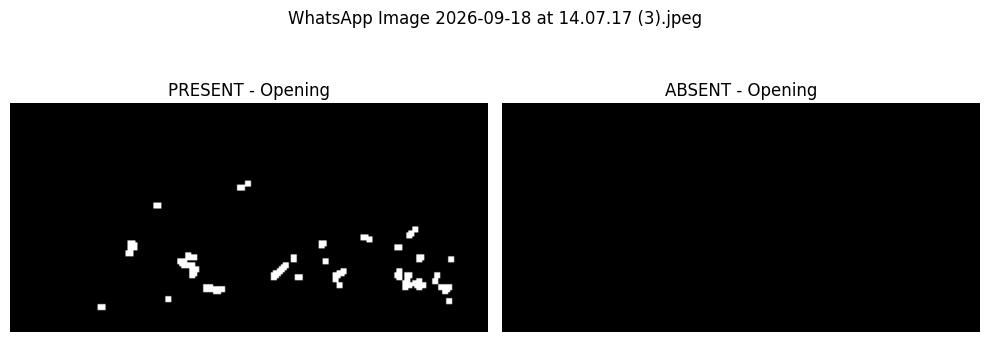

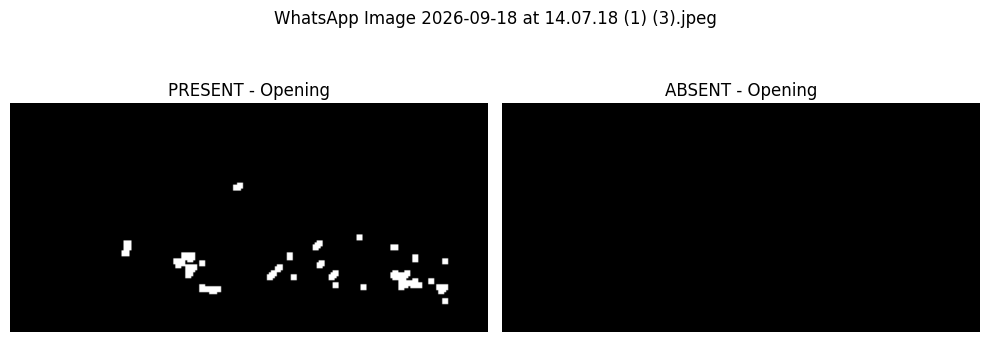

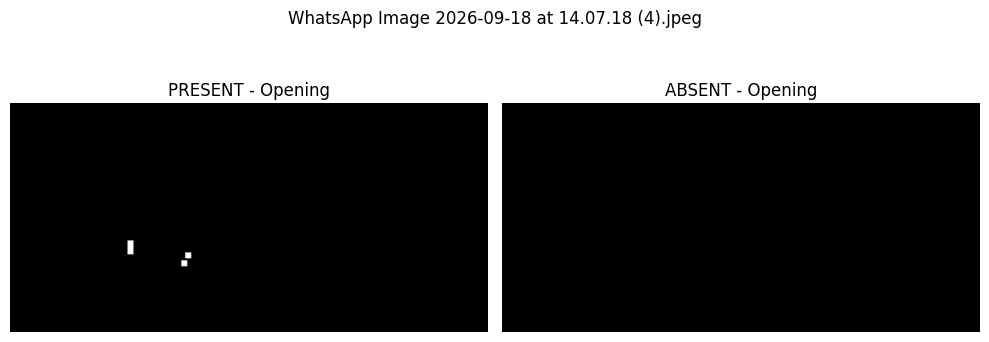

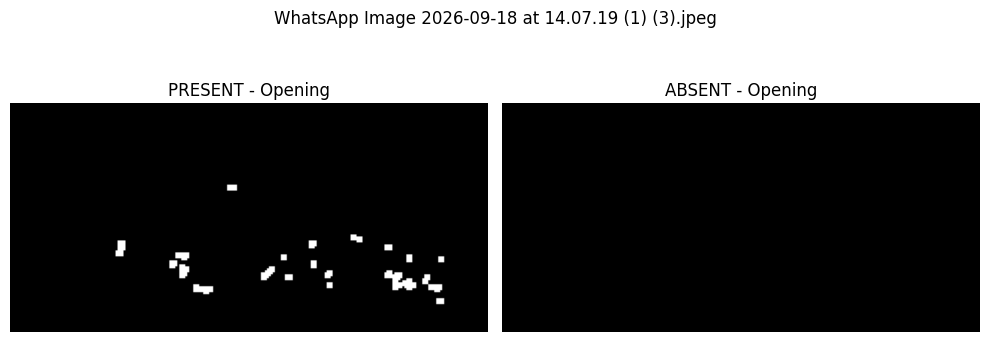

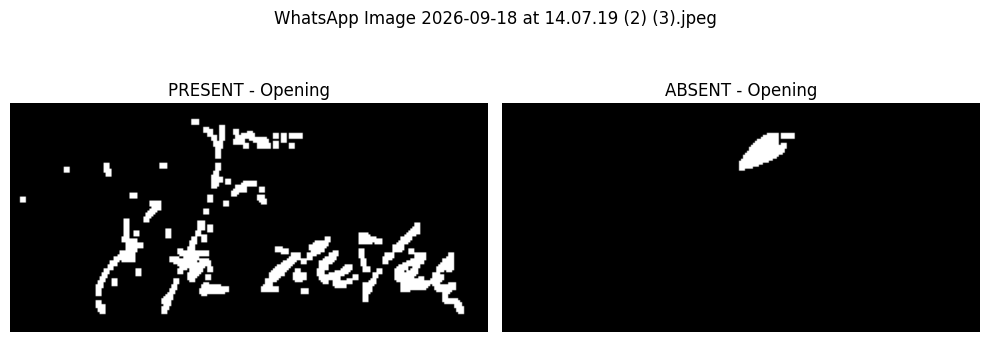

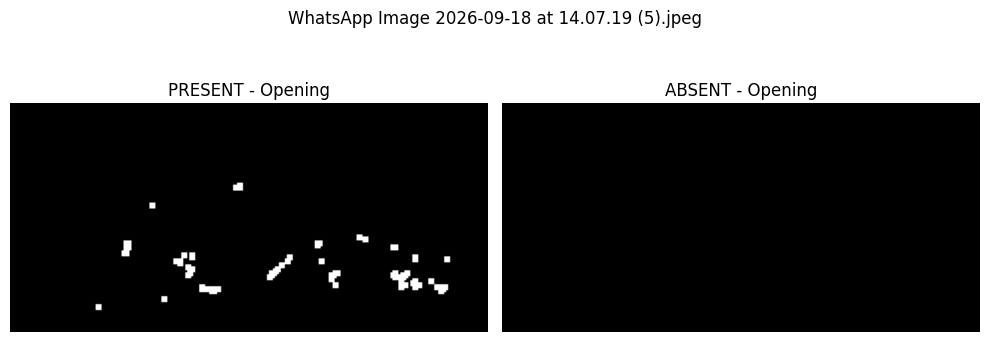

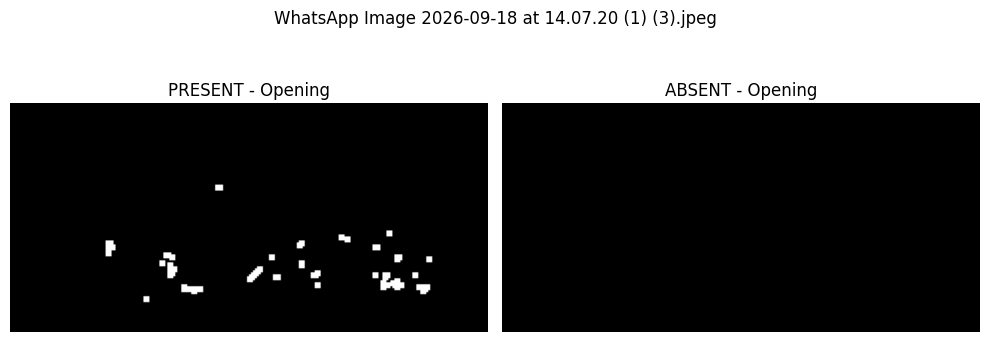

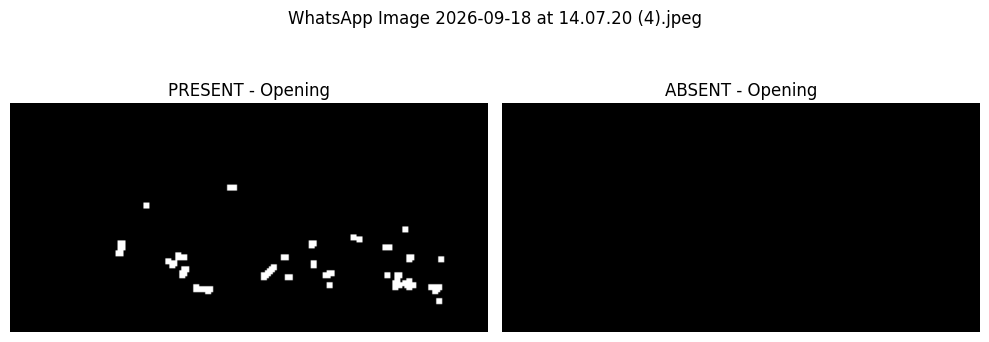

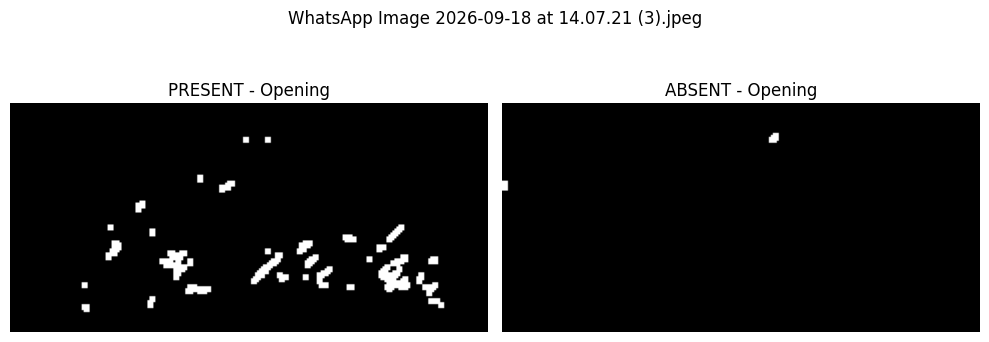

In [59]:
for filename in present_opening.keys():

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 4)
    )

    axes[0].imshow(
        present_opening[filename],
        cmap="gray"
    )
    axes[0].set_title("PRESENT - Opening")
    axes[0].axis("off")

    axes[1].imshow(
        absent_opening[filename],
        cmap="gray"
    )
    axes[1].set_title("ABSENT - Opening")
    axes[1].axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [60]:
present_closing = {}
absent_closing = {}

for filename in present_opening.keys():

    present_closing[filename] = cv2.morphologyEx(
        present_opening[filename],
        cv2.MORPH_CLOSE,
        kernel
    )

    absent_closing[filename] = cv2.morphologyEx(
        absent_opening[filename],
        cv2.MORPH_CLOSE,
        kernel
    )

print("Closing selesai.")

Closing selesai.


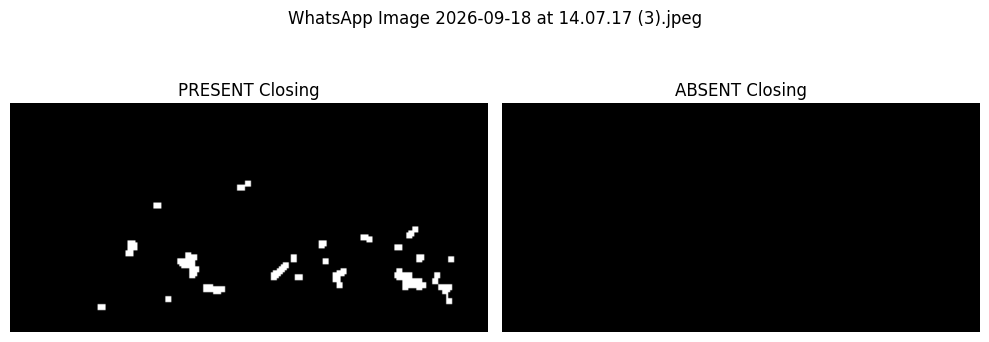

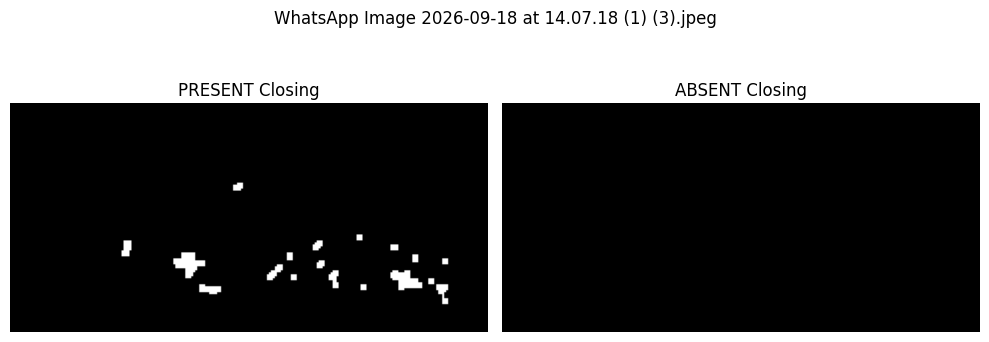

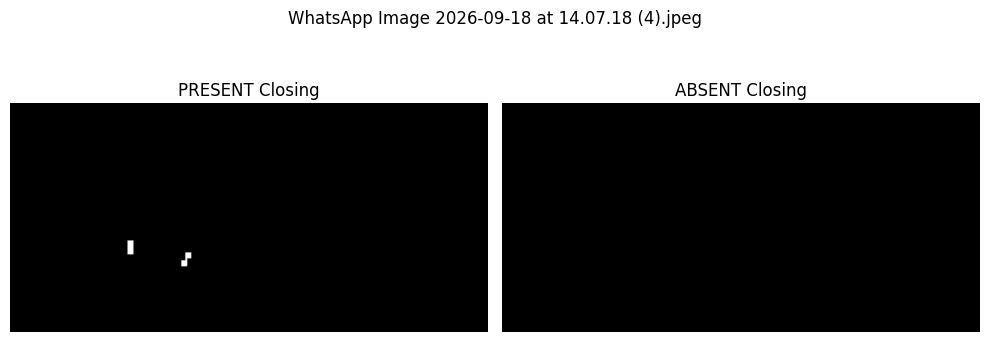

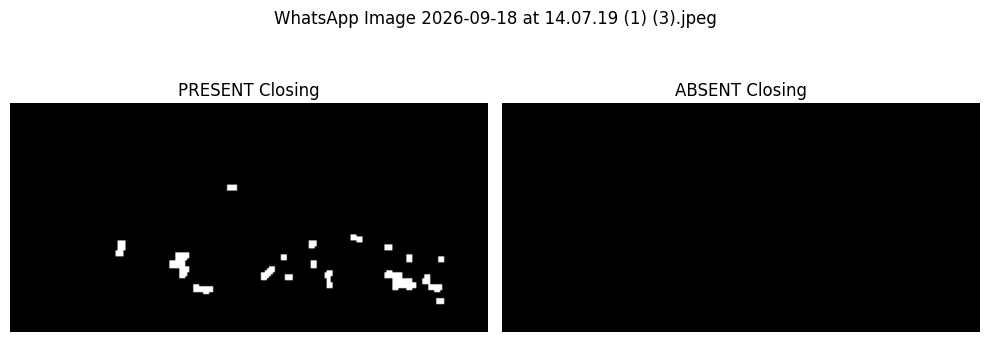

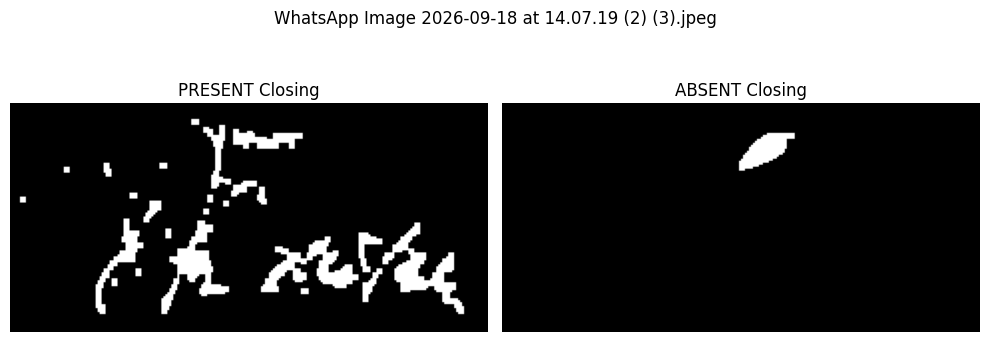

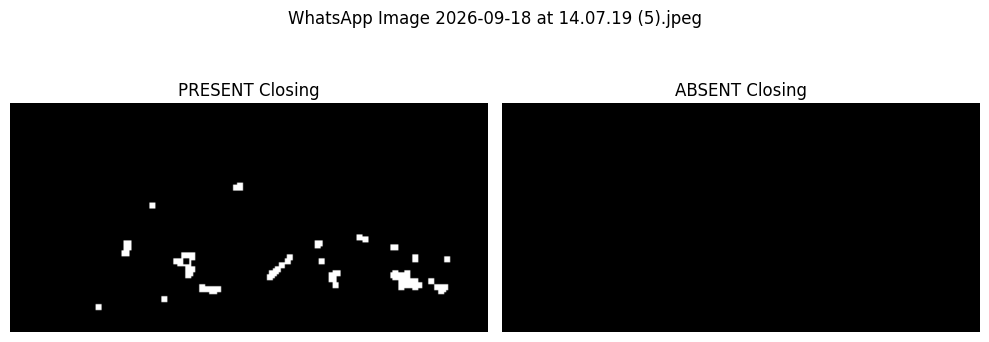

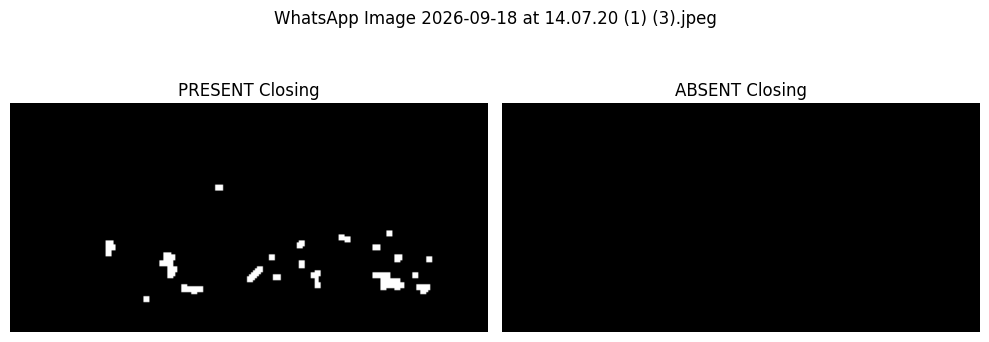

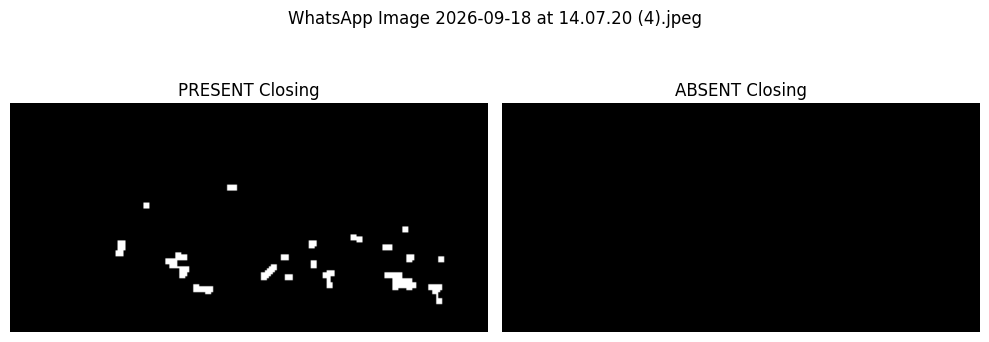

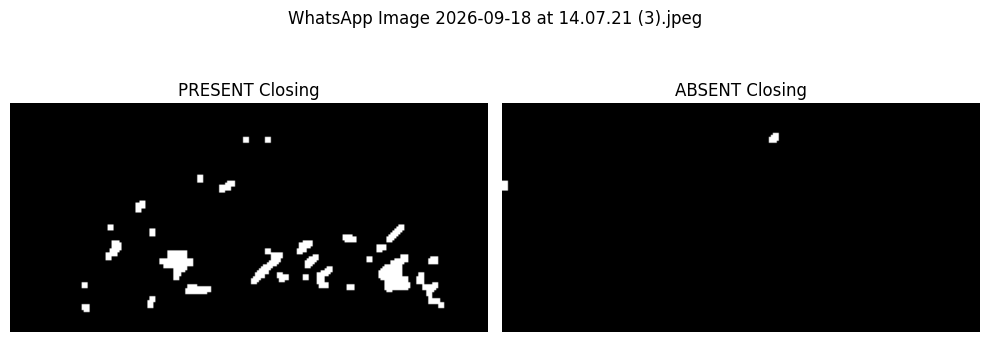

In [79]:
for filename in present_closing.keys():

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 4)
    )

    axes[0].imshow(
        present_closing[filename],
        cmap="gray"
    )
    axes[0].set_title("PRESENT Closing")
    axes[0].axis("off")

    axes[1].imshow(
        absent_closing[filename],
        cmap="gray"
    )
    axes[1].set_title("ABSENT Closing")
    axes[1].axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [62]:
foreground_results = []

for filename in present_closing.keys():

    present_pixels = np.sum(
        present_closing[filename] == 255
    )

    absent_pixels = np.sum(
        absent_closing[filename] == 255
    )

    total_pixels = present_closing[filename].size

    present_percentage = (
        present_pixels / total_pixels
    ) * 100

    absent_percentage = (
        absent_pixels / total_pixels
    ) * 100

    foreground_results.append({
        "Nama File": filename,
        "PRESENT Pixel": present_pixels,
        "PRESENT (%)": present_percentage,
        "ABSENT Pixel": absent_pixels,
        "ABSENT (%)": absent_percentage
    })

foreground_df = pd.DataFrame(
    foreground_results
)

foreground_df

,Nama File,PRESENT Pixel,PRESENT (%),ABSENT Pixel,ABSENT (%)
0,WhatsApp Image 2026-09-18 at 14.07.17 (3).jpeg,576,2.086957,0,0.000000
1,WhatsApp Image 2026-09-18 at 14.07.18 (1) (3)....,512,1.855072,0,0.000000
2,WhatsApp Image 2026-09-18 at 14.07.18 (4).jpeg,40,0.144928,0,0.000000
3,WhatsApp Image 2026-09-18 at 14.07.19 (1) (3)....,467,1.692029,0,0.000000
4,WhatsApp Image 2026-09-18 at 14.07.19 (2) (3)....,2665,9.655797,286,1.036232
5,WhatsApp Image 2026-09-18 at 14.07.19 (5).jpeg,495,1.793478,0,0.000000
6,WhatsApp Image 2026-09-18 at 14.07.20 (1) (3)....,461,1.670290,0,0.000000
7,WhatsApp Image 2026-09-18 at 14.07.20 (4).jpeg,478,1.731884,0,0.000000
8,WhatsApp Image 2026-09-18 at 14.07.21 (3).jpeg,1052,3.811594,36,0.130435


In [65]:
thresholds = [
    0.1,
    0.2,
    0.3,
    0.5,
    0.7,
    1.0,
    1.5,
    2.0,
    3.0
]

for threshold in thresholds:

    print(f"\nThreshold = {threshold}%")

    for _, row in foreground_df.iterrows():

        present_pred = (
            row["PRESENT (%)"] > threshold
        )

        absent_pred = (
            row["ABSENT (%)"] > threshold
        )

        print(
            row["Nama File"][:25],
            "| PRESENT:",
            "PRESENT" if present_pred else "ABSENT",
            "| ABSENT:",
            "PRESENT" if absent_pred else "ABSENT"
        )


Threshold = 0.1%
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: PRESENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: PRESENT

Threshold = 0.2%
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: ABSENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: PRESENT
WhatsApp Image 2026-09-18 | PRESENT: PRESENT | ABSENT: ABSENT
WhatsApp Image 2026-09-18 | PRES

In [66]:
print(
    "PRESENT minimum :",
    foreground_df["PRESENT (%)"].min(),
    "%"
)

print(
    "PRESENT maksimum:",
    foreground_df["PRESENT (%)"].max(),
    "%"
)

print(
    "ABSENT minimum  :",
    foreground_df["ABSENT (%)"].min(),
    "%"
)

print(
    "ABSENT maksimum :",
    foreground_df["ABSENT (%)"].max(),
    "%"
)

PRESENT minimum : 0.14492753623188406 %
PRESENT maksimum: 9.655797101449275 %
ABSENT minimum  : 0.0 %
ABSENT maksimum : 1.036231884057971 %


In [68]:
thresholds = np.arange(0.0, 2.1, 0.1)

hasil_threshold = []

for threshold in thresholds:

    benar_present = 0
    benar_absent = 0

    for _, row in foreground_df.iterrows():

        # PRESENT seharusnya diklasifikasikan PRESENT
        pred_present = row["PRESENT (%)"] > threshold

        # ABSENT seharusnya diklasifikasikan ABSENT
        pred_absent = row["ABSENT (%)"] <= threshold

        if pred_present:
            benar_present += 1

        if pred_absent:
            benar_absent += 1

    total_benar = benar_present + benar_absent
    total_data = len(foreground_df) * 2

    accuracy = (
        total_benar / total_data
    ) * 100

    hasil_threshold.append({
        "Threshold (%)": threshold,
        "Benar PRESENT": benar_present,
        "Benar ABSENT": benar_absent,
        "Total Benar": total_benar,
        "Accuracy (%)": accuracy
    })

threshold_df = pd.DataFrame(hasil_threshold)

threshold_df

,Threshold (%),Benar PRESENT,Benar ABSENT,Total Benar,Accuracy (%)
0,0.0,9,7,16,88.888889
1,0.1,9,7,16,88.888889
2,0.2,8,8,16,88.888889
3,0.3,8,8,16,88.888889
4,0.4,8,8,16,88.888889
5,0.5,8,8,16,88.888889
6,0.6,8,8,16,88.888889
7,0.7,8,8,16,88.888889
8,0.8,8,8,16,88.888889
9,0.9,8,8,16,88.888889


In [69]:
best_result = threshold_df.loc[
    threshold_df["Accuracy (%)"].idxmax()
]

print("Threshold yang menghasilkan accuracy tertinggi:")
print()

print(
    "Threshold :",
    best_result["Threshold (%)"],
    "%"
)

print(
    "Benar PRESENT :",
    int(best_result["Benar PRESENT"])
)

print(
    "Benar ABSENT :",
    int(best_result["Benar ABSENT"])
)

print(
    "Total Benar :",
    int(best_result["Total Benar"])
)

print(
    "Accuracy :",
    best_result["Accuracy (%)"],
    "%"
)

Threshold yang menghasilkan accuracy tertinggi:

Threshold : 1.1 %
Benar PRESENT : 8
Benar ABSENT : 9
Total Benar : 17
Accuracy : 94.44444444444444 %


In [70]:
classification_threshold = 1.1

print("Rule klasifikasi:")
print(f"Foreground > {classification_threshold}%  → SIGNATURE PRESENT")
print(f"Foreground <= {classification_threshold}% → SIGNATURE ABSENT")

Rule klasifikasi:
Foreground > 1.1%  → SIGNATURE PRESENT
Foreground <= 1.1% → SIGNATURE ABSENT


In [71]:
present_predictions = []

for _, row in foreground_df.iterrows():

    foreground = row["PRESENT (%)"]

    if foreground > classification_threshold:
        prediction = "SIGNATURE PRESENT"
    else:
        prediction = "SIGNATURE ABSENT"

    present_predictions.append({
        "Nama File": row["Nama File"],
        "Foreground (%)": foreground,
        "Prediksi": prediction
    })

present_prediction_df = pd.DataFrame(
    present_predictions
)

present_prediction_df

,Nama File,Foreground (%),Prediksi
0,WhatsApp Image 2026-09-18 at 14.07.17 (3).jpeg,2.086957,SIGNATURE PRESENT
1,WhatsApp Image 2026-09-18 at 14.07.18 (1) (3)....,1.855072,SIGNATURE PRESENT
2,WhatsApp Image 2026-09-18 at 14.07.18 (4).jpeg,0.144928,SIGNATURE ABSENT
3,WhatsApp Image 2026-09-18 at 14.07.19 (1) (3)....,1.692029,SIGNATURE PRESENT
4,WhatsApp Image 2026-09-18 at 14.07.19 (2) (3)....,9.655797,SIGNATURE PRESENT
5,WhatsApp Image 2026-09-18 at 14.07.19 (5).jpeg,1.793478,SIGNATURE PRESENT
6,WhatsApp Image 2026-09-18 at 14.07.20 (1) (3)....,1.670290,SIGNATURE PRESENT
7,WhatsApp Image 2026-09-18 at 14.07.20 (4).jpeg,1.731884,SIGNATURE PRESENT
8,WhatsApp Image 2026-09-18 at 14.07.21 (3).jpeg,3.811594,SIGNATURE PRESENT


In [72]:
absent_predictions = []

for _, row in foreground_df.iterrows():

    foreground = row["ABSENT (%)"]

    if foreground > classification_threshold:
        prediction = "SIGNATURE PRESENT"
    else:
        prediction = "SIGNATURE ABSENT"

    absent_predictions.append({
        "Nama File": row["Nama File"],
        "Foreground (%)": foreground,
        "Prediksi": prediction
    })

absent_prediction_df = pd.DataFrame(
    absent_predictions
)

absent_prediction_df

,Nama File,Foreground (%),Prediksi
0,WhatsApp Image 2026-09-18 at 14.07.17 (3).jpeg,0.000000,SIGNATURE ABSENT
1,WhatsApp Image 2026-09-18 at 14.07.18 (1) (3)....,0.000000,SIGNATURE ABSENT
2,WhatsApp Image 2026-09-18 at 14.07.18 (4).jpeg,0.000000,SIGNATURE ABSENT
3,WhatsApp Image 2026-09-18 at 14.07.19 (1) (3)....,0.000000,SIGNATURE ABSENT
4,WhatsApp Image 2026-09-18 at 14.07.19 (2) (3)....,1.036232,SIGNATURE ABSENT
5,WhatsApp Image 2026-09-18 at 14.07.19 (5).jpeg,0.000000,SIGNATURE ABSENT
6,WhatsApp Image 2026-09-18 at 14.07.20 (1) (3)....,0.000000,SIGNATURE ABSENT
7,WhatsApp Image 2026-09-18 at 14.07.20 (4).jpeg,0.000000,SIGNATURE ABSENT
8,WhatsApp Image 2026-09-18 at 14.07.21 (3).jpeg,0.130435,SIGNATURE ABSENT


In [73]:
evaluation_df = pd.DataFrame({
    "Nama File": foreground_df["Nama File"],
    "Aktual PRESENT": ["SIGNATURE PRESENT"] * len(foreground_df),
    "Prediksi PRESENT": present_prediction_df["Prediksi"],
    "Aktual ABSENT": ["SIGNATURE ABSENT"] * len(foreground_df),
    "Prediksi ABSENT": absent_prediction_df["Prediksi"]
})

evaluation_df

,Nama File,Aktual PRESENT,Prediksi PRESENT,Aktual ABSENT,Prediksi ABSENT
0,WhatsApp Image 2026-09-18 at 14.07.17 (3).jpeg,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
1,WhatsApp Image 2026-09-18 at 14.07.18 (1) (3)....,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
2,WhatsApp Image 2026-09-18 at 14.07.18 (4).jpeg,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT,SIGNATURE ABSENT
3,WhatsApp Image 2026-09-18 at 14.07.19 (1) (3)....,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
4,WhatsApp Image 2026-09-18 at 14.07.19 (2) (3)....,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
5,WhatsApp Image 2026-09-18 at 14.07.19 (5).jpeg,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
6,WhatsApp Image 2026-09-18 at 14.07.20 (1) (3)....,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
7,WhatsApp Image 2026-09-18 at 14.07.20 (4).jpeg,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT
8,WhatsApp Image 2026-09-18 at 14.07.21 (3).jpeg,SIGNATURE PRESENT,SIGNATURE PRESENT,SIGNATURE ABSENT,SIGNATURE ABSENT


Confusion Matrix:
[[8 1]
 [0 9]]
TP = 8
TN = 9
FP = 0
FN = 1


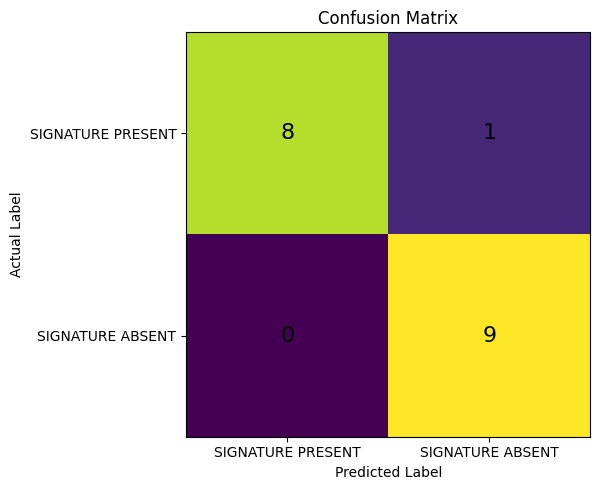

Accuracy  : 94.44%
Precision : 100.00%
Recall    : 88.89%


In [75]:
from sklearn.metrics import confusion_matrix

# Label aktual
y_true = (
    ["SIGNATURE PRESENT"] * len(foreground_df)
    + ["SIGNATURE ABSENT"] * len(foreground_df)
)

# Label prediksi
y_pred = (
    present_prediction_df["Prediksi"].tolist()
    + absent_prediction_df["Prediksi"].tolist()
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[
        "SIGNATURE PRESENT",
        "SIGNATURE ABSENT"
    ]
)

print("Confusion Matrix:")
print(cm)

TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

print("TP =", TP)
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["SIGNATURE PRESENT", "SIGNATURE ABSENT"]
)

plt.yticks(
    [0, 1],
    ["SIGNATURE PRESENT", "SIGNATURE ABSENT"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()
plt.show()

accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP) if (TP + FP) != 0 else 0

recall = TP / (TP + FN) if (TP + FN) != 0 else 0

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")

In [76]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        labels=[
            "SIGNATURE PRESENT",
            "SIGNATURE ABSENT"
        ]
    )
)

                   precision    recall  f1-score   support

SIGNATURE PRESENT       1.00      0.89      0.94         9
 SIGNATURE ABSENT       0.90      1.00      0.95         9

         accuracy                           0.94        18
        macro avg       0.95      0.94      0.94        18
     weighted avg       0.95      0.94      0.94        18



# How to Run Program

Program ini digunakan untuk mendeteksi keberadaan tanda tangan pada area tanda tangan ijazah menggunakan metode pengolahan citra digital.

## Langkah Menjalankan Program

Jalankan cell upload kemudian pilih gambar ijazah yang akan digunakan sebagai input. di sini kita dapat mengapload sekaligus 9 ijazah

Program akan membaca gambar yang telah di-upload dan menyimpannya untuk proses selanjutnya.

### 4. Menentukan Area Tanda Tangan (ROI)

Program mengambil area tanda tangan menggunakan koordinat Region of Interest (ROI).

Area yang digunakan adalah:

- X1 = 650
- Y1 = 475
- X2 = 890
- Y2 = 590

Sehingga area tanda tangan yang diproses berukuran 240 × 115 piksel.

### 5. Membuat Data PRESENT dan ABSENT

Program menggunakan area ROI yang sama untuk membuat dua kondisi:

- **PRESENT** → area tanda tangan asli.
- **ABSENT** → area tanda tangan dihilangkan menggunakan proses inpainting.

Hal ini dilakukan agar perbandingan kondisi tanda tangan menggunakan area gambar yang sama.

### 6. Konversi Grayscale

Citra ROI dikonversi dari RGB/BGR menjadi grayscale.

Grayscale digunakan karena proses thresholding bekerja berdasarkan intensitas piksel.

### 7. Thresholding

Program menggunakan dua metode thresholding:

- Global Threshold dengan nilai threshold 150.
- Otsu Threshold.

Thresholding digunakan untuk memisahkan foreground dari background sehingga keberadaan tanda tangan dapat dianalisis berdasarkan jumlah piksel foreground.

### 8. Morphological Processing

Setelah thresholding, dilakukan operasi morfologi:

- Opening
- Closing

Proses ini digunakan untuk mengurangi noise dan memperbaiki bentuk objek hasil thresholding.

### 9. Menghitung Foreground Pixel

Program menghitung jumlah piksel foreground dan persentasenya terhadap seluruh piksel ROI.

Persentase foreground digunakan sebagai karakteristik untuk membedakan kondisi tanda tangan PRESENT dan ABSENT.

### 10. Menentukan Threshold Klasifikasi

Program melakukan pengujian beberapa nilai threshold untuk mencari nilai yang memberikan hasil klasifikasi terbaik pada data pengujian.

Berdasarkan hasil pengujian, digunakan threshold:

**1.1%**

Aturan klasifikasi yang digunakan adalah:

```text
Jika foreground percentage > 1.1%
    → SIGNATURE PRESENT

Jika foreground percentage <= 1.1%
    → SIGNATURE ABSENT